# NeuroMap - Brain Tumor CNN Training (Jupyter Notebook)

Ye notebook seedha **train + test** karega, terminal me kuch chalane ki zaroorat nahi.
Bas har cell ko upar se niche RUN karte jao (Shift+Enter).

**Paths already set hain:**
- Training: `C:\Users\amits\Downloads\Cornerstone\dataset\Training`
- Testing: `C:\Users\amits\Downloads\Cornerstone\dataset\Testing`

Trained model save hoga: `C:\Users\amits\Downloads\Cornerstone\model\brain_tumor_cnn.keras`


## 1. Imports

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))


TensorFlow version: 2.21.0
GPU available: []


## 2. Config — paths, image size, classes

In [2]:
# ---- PATHS (already set for your machine) ----
TRAIN_DIR = r"C:\Users\amits\Downloads\Cornerstone\dataset\Training"
TEST_DIR  = r"C:\Users\amits\Downloads\Cornerstone\dataset\Testing"
MODEL_OUT_DIR = r"C:\Users\amits\Downloads\Cornerstone\model"
MODEL_OUT_PATH = os.path.join(MODEL_OUT_DIR, "app.keras")

os.makedirs(MODEL_OUT_DIR, exist_ok=True)

IMG_SIZE = 150
BATCH_SIZE = 32
EPOCHS = 40

CLASS_NAMES = ["glioma", "meningioma", "notumor", "pituitary"]
LAST_CONV_LAYER_NAME = "last_conv"

print("Training dir:", TRAIN_DIR)
print("Testing dir :", TEST_DIR)
print("Model will be saved to:", MODEL_OUT_PATH)


Training dir: C:\Users\amits\Downloads\Cornerstone\dataset\Training
Testing dir : C:\Users\amits\Downloads\Cornerstone\dataset\Testing
Model will be saved to: C:\Users\amits\Downloads\Cornerstone\model\app.keras


## 3. Load datasets

In [3]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    validation_split=0.1,
    subset="training",
    seed=42,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="categorical",
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    validation_split=0.1,
    subset="validation",
    seed=42,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="categorical",
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=False,
)

print("Detected classes:", train_ds.class_names)
assert train_ds.class_names == CLASS_NAMES, (
    f"Class order mismatch! Found {train_ds.class_names}, expected {CLASS_NAMES}. "
    f"Update CLASS_NAMES in this notebook (Cell 2) AND in streamlit's model_utils.py to match."
)


Found 5600 files belonging to 4 classes.
Using 5040 files for training.
Found 5600 files belonging to 4 classes.
Using 560 files for validation.
Found 1600 files belonging to 4 classes.
Detected classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


## 4. Preprocess: normalize + light augmentation

In [4]:
normalization_layer = tf.keras.layers.Rescaling(1.0 / 255)

augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.1),
])

train_ds = train_ds.map(lambda x, y: (augmentation(x, training=True), y))
train_ds = train_ds.map(lambda x, y: (normalization_layer(x), y))
val_ds = val_ds.map(lambda x, y: (normalization_layer(x), y))
test_ds = test_ds.map(lambda x, y: (normalization_layer(x), y))

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

print("Datasets ready.")


Datasets ready.


## 5. Build CNN model (from scratch)

In [5]:
from tensorflow.keras import layers, models

def build_cnn_model(input_shape=(IMG_SIZE, IMG_SIZE, 3), num_classes=4):
    model = models.Sequential([
        layers.Input(shape=input_shape),

        # Block 1
        layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2, 2),

        # Block 2
        layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2, 2),

        # Block 3
        layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2, 2),

        # Block 4 - LAST conv layer (Grad-CAM uses this)
        layers.Conv2D(256, (3, 3), activation="relu", padding="same", name=LAST_CONV_LAYER_NAME),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2, 2),

        layers.GlobalAveragePooling2D(),
        layers.Dense(256, activation="relu"),
        layers.Dropout(0.4),
        layers.Dense(num_classes, activation="softmax"),
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
        loss="categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model

model = build_cnn_model()
model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 150, 150, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 150, 150, 32)        │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 75, 75, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 75, 75, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 75, 75, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 37, 37, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 37, 37, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 37, 37, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 18, 18, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ last_conv (Conv2D)                   │ (None, 18, 18, 256)         │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 18, 18, 256)         │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 9, 9, 256)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 256)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 256)                 │          65,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 4)                   │           1,028 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 457,156 (1.74 MB)

 Trainable params: 456,196 (1.74 MB)

 Non-trainable params: 960 (3.75 KB)

## 6. Train the model

In [6]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(patience=6, restore_best_weights=True, monitor="val_accuracy"),
    tf.keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=3, monitor="val_loss"),
    tf.keras.callbacks.ModelCheckpoint(MODEL_OUT_PATH, save_best_only=True, monitor="val_accuracy"),
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
)


Epoch 1/40


C:\Users\amits\anaconda3\envs\ml_env\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


158/158 ━━━━━━━━━━━━━━━━━━━━ 177s 1s/step - accuracy: 0.6653 - loss: 0.8388 - val_accuracy: 0.2893 - val_loss: 1.3674 - learning_rate: 1.0000e-04
Epoch 2/40
158/158 ━━━━━━━━━━━━━━━━━━━━ 169s 1s/step - accuracy: 0.7536 - loss: 0.6271 - val_accuracy: 0.4089 - val_loss: 1.3745 - learning_rate: 1.0000e-04
Epoch 3/40
158/158 ━━━━━━━━━━━━━━━━━━━━ 170s 1s/step - accuracy: 0.7861 - loss: 0.5402 - val_accuracy: 0.7571 - val_loss: 0.7223 - learning_rate: 1.0000e-04
Epoch 4/40
158/158 ━━━━━━━━━━━━━━━━━━━━ 164s 1s/step - accuracy: 0.8206 - loss: 0.4755 - val_accuracy: 0.8321 - val_loss: 0.4416 - learning_rate: 1.0000e-04
Epoch 5/40
158/158 ━━━━━━━━━━━━━━━━━━━━ 166s 1s/step - accuracy: 0.8313 - loss: 0.4383 - val_accuracy: 0.7500 - val_loss: 0.6998 - learning_rate: 1.0000e-04
Epoch 6/40
158/158 ━━━━━━━━━━━━━━━━━━━━ 166s 1s/step - accuracy: 0.8454 - loss: 0.4047 - val_accuracy: 0.7911 - val_loss: 0.5412 - learning_rate: 1.0000e-04
Epoch 7/40
158/158 ━━━━━━━━━━━━━━━━━━━━ 203s 1s/step - accuracy: 0.85

## 7. Plot accuracy / loss curves

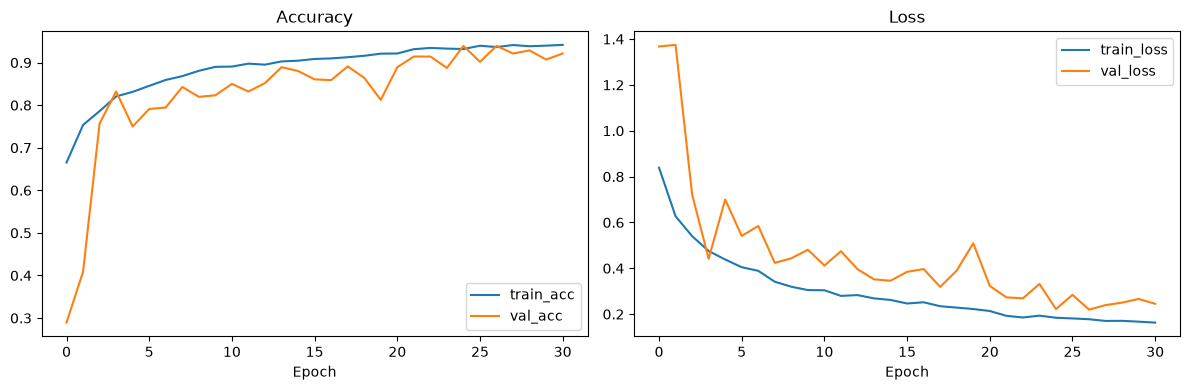

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["accuracy"], label="train_acc")
axes[0].plot(history.history["val_accuracy"], label="val_acc")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history.history["loss"], label="train_loss")
axes[1].plot(history.history["val_loss"], label="val_loss")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()


## 8. Test / Evaluate on Testing folder


Classification Report:

              precision    recall  f1-score   support

      glioma       0.95      0.65      0.77       400
  meningioma       0.81      0.72      0.76       400
     notumor       0.76      1.00      0.87       400
   pituitary       0.88      0.99      0.93       400

    accuracy                           0.84      1600
   macro avg       0.85      0.84      0.83      1600
weighted avg       0.85      0.84      0.83      1600



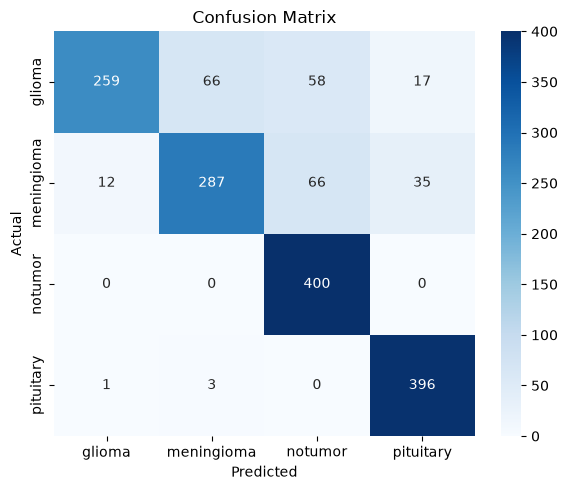

In [10]:
y_true = []
y_pred = []

for images, labels in test_ds:
    preds = model.predict(images, verbose=0)
    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred.extend(np.argmax(preds, axis=1))

print("\nClassification Report:\n")
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()


## 9. Save final model (for Streamlit app)

In [9]:
model.save(MODEL_OUT_PATH)
print(f"Model saved to: {MODEL_OUT_PATH}")
print("Ab Streamlit app chala sakte ho: streamlit run streamlit_app.py")


Model saved to: C:\Users\amits\Downloads\Cornerstone\model\app.keras
Ab Streamlit app chala sakte ho: streamlit run streamlit_app.py
